기준연월,처리TEU,부두가동률,선박수,보정재항시간중앙값
2022-01,248000,139.71,71,28.38
2022-02,227000,141.58,57,31.11
2022-03,201000,113.24,61,25.58
2022-04,233000,135.64,63,30.87
2022-05,230000,129.57,58,31.85
2022-06,214000,124.58,57,28.01
2022-07,254000,143.09,59,34.19
2022-08,238000,134.08,60,31.37
2022-09,195000,113.52,48,26.76
2022-10,211000,118.87,54,25.00


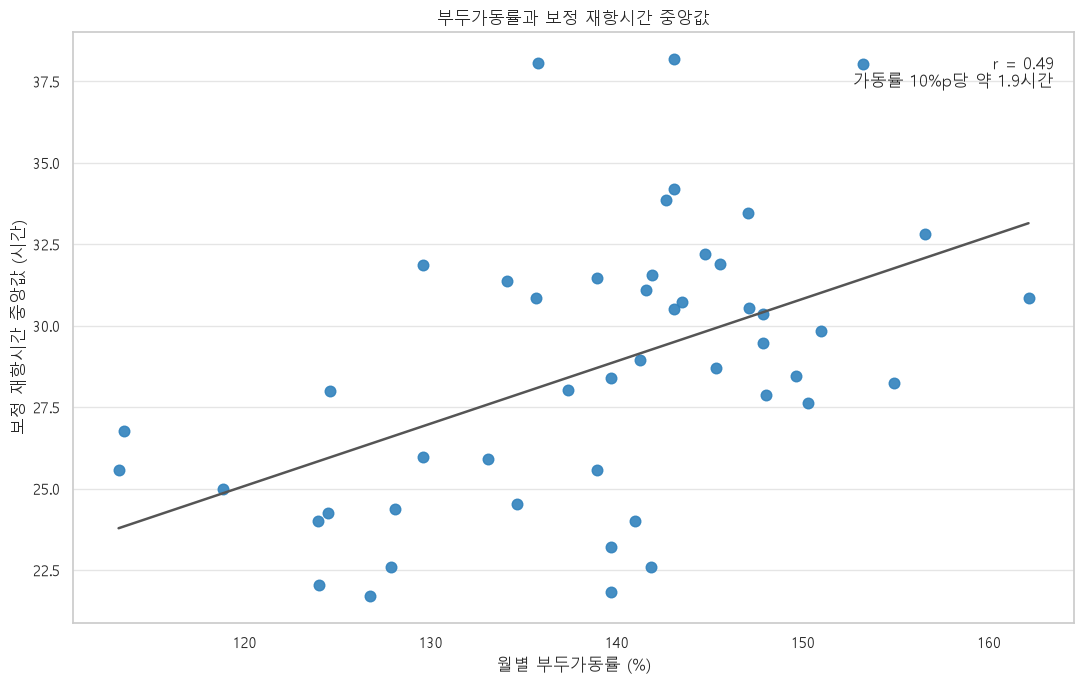

In [2]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = Path("C:/final")

DATA_PATH = PROJECT_ROOT / "data"
record = pd.read_csv(DATA_PATH / "record.csv", encoding="utf-8-sig")
port_month = pd.read_csv(DATA_PATH / "port_month.csv", encoding="cp949")

# 월별 처리 TEU와 부두가동률
port_month["기준연월"] = pd.to_datetime(
    dict(
        year=port_month["기준년도"],
        month=port_month["월"],
        day=1,
    )
)
port_month = port_month[
    port_month["기준연월"].dt.year.between(2022, 2025)
].copy()
port_month["처리TEU"] = pd.to_numeric(
    port_month["신항1부두"],
    errors="coerce",
) * 1000

days = port_month["기준연월"].dt.days_in_month
year_days = port_month["기준연월"].dt.is_leap_year.map(
    {True: 366, False: 365}
)
port_month["부두가동률"] = (
    port_month["처리TEU"]
    / (2_090_000 * days / year_days)
    * 100
)

# 신항 1부두 선박별 보정 재항시간
record["입항일시"] = pd.to_datetime(record["입항일시"], errors="coerce")
record["총톤수"] = pd.to_numeric(
    record["총톤수"].astype(str).str.replace(",", "", regex=False),
    errors="coerce",
)
record["재항시간"] = pd.to_numeric(
    record["재항시간"],
    errors="coerce",
)
record["기준연월"] = (
    record["입항일시"].dt.to_period("M").dt.to_timestamp()
)

record = record[
    record["계선장소"].astype(str).str.contains("신항 1부두", na=False)
    & record["기준연월"].dt.year.between(2022, 2025)
    & record["총톤수"].gt(0)
    & record["재항시간"].notna()
].copy()

record["보정재항시간"] = record["재항시간"] * (
    74_739 / record["총톤수"]
) ** 0.244

월별_재항시간 = (
    record.groupby("기준연월", as_index=False)
    .agg(
        선박수=("보정재항시간", "count"),
        보정재항시간중앙값=("보정재항시간", "median"),
    )
)

월별_분석 = (
    port_month[["기준연월", "처리TEU", "부두가동률"]]
    .merge(월별_재항시간, on="기준연월", how="inner")
    .sort_values("기준연월")
)

목록 = 월별_분석.copy()
목록["기준연월"] = 목록["기준연월"].dt.strftime("%Y-%m")
display(목록.style.format(precision=2).hide(axis="index"))

# 부두가동률과 보정 재항시간 중앙값 산점도
x = 월별_분석["부두가동률"]
y = 월별_분석["보정재항시간중앙값"]
상관계수 = x.corr(y)
기울기 = x.cov(y) / x.var()

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

fig, ax = plt.subplots(figsize=(11, 7))
sns.regplot(
    x=x,
    y=y,
    ax=ax,
    ci=None,
    scatter_kws={"s": 58, "color": "#3182bd", "alpha": 0.9},
    line_kws={"color": "#555555", "linewidth": 1.8},
)

ax.set_title("부두가동률과 보정 재항시간 중앙값")
ax.set_xlabel("월별 부두가동률 (%)")
ax.set_ylabel("보정 재항시간 중앙값 (시간)")
ax.text(
    0.98,
    0.96,
    f"r = {상관계수:.2f}\n가동률 10%p당 약 {기울기 * 10:.1f}시간",
    transform=ax.transAxes,
    ha="right",
    va="top",
)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

